In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
) 

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor


In [ ]:
# Load the feature engineer datasets

df = pd.read_csv("../Data/Cleaned/ChargingRecords_Feature_Engineered.csv")

# Checking the dataset

print("Dataset Shape : " , df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

In [ ]:
# Independent features
X = df.drop(columns=["Demand"])

# Dependent target
y = df["Demand"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

In [ ]:
# Split the dataset

X_train, X_test, y_train, y_test= train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Check split dimension

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)



In [ ]:
# Initialize regression models

models ={
    "Linear Regression": LinearRegression(),
    
    "Decision Tree " : DecisionTreeRegressor(
        random_state=42
        ),

    "Random Forest": RandomForestRegressor(
        random_state=42,
        n_estimators=100,
        n_jobs =-1
    ),
    
    "Gradient Boosting" : GradientBoostingRegressor(
        random_state=42,
    )
}

print("Regression models initialized:")
for name in models:
    print("-", name)

In [ ]:
# Train all the regression models

for name, model in models.items():
    print(f"Training {name}...")
    
    model.fit(X_train , y_train)
    
print("\nAll models trained successfully.")

In [ ]:
# Store predictions and evaluation results
predictions = {}
results = []

for name, model in models.items():

    # Generate predictions
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create comparison dataframe
results_df = pd.DataFrame(results)

# Sort by RMSE
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df.round(4))

In [ ]:
# Actual vs Predicted values
best_model_name = "Gradient Boosting"
y_pred_best = predictions[best_model_name]

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_best,
    alpha=0.4
)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred_best.min())
max_value = max(y_test.max(), y_pred_best.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.title("Actual vs Predicted Demand - Gradient Boosting")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
models["XGBoost"] = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
    objective="reg:squarederror"
)

models["LightGBM"] = LGBMRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

print("XGBoost and LightGBM initialized successfully!")

In [ ]:
for name in ["XGBoost", "LightGBM"]:
    print(f"Training {name}...")
    models[name].fit(X_train, y_train)

print("\nBoth models trained successfully!")

In [ ]:
# Store predictions and evaluation results
predictions = {}
results = []

for name, model in models.items():

    # Generate predictions
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create comparison dataframe
results_df = pd.DataFrame(results)

# Sort by RMSE
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df.round(4))

In [ ]:
xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV RMSE:", -random_search.best_score_)

In [ ]:
# Get the best tuned model
best_xgb_model = random_search.best_estimator_

# Predict on test data
y_pred_tuned = best_xgb_model.predict(X_test)

# Calculate evaluation metrics
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_mse = mean_squared_error(y_test, y_pred_tuned)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, y_pred_tuned)

# Display results
tuned_results = pd.DataFrame([{
    "Model": "Tuned XGBoost",
    "MAE": tuned_mae,
    "MSE": tuned_mse,
    "RMSE": tuned_rmse,
    "R2 Score": tuned_r2
}])

display(tuned_results.round(4))

In [ ]:
comparison = pd.DataFrame([
    {
        "Model": "Original XGBoost",
        "RMSE": results_df.loc[
            results_df["Model"] == "XGBoost", "RMSE"
        ].iloc[0],
        "R2 Score": results_df.loc[
            results_df["Model"] == "XGBoost", "R2 Score"
        ].iloc[0]
    },
    {
        "Model": "Tuned XGBoost",
        "RMSE": tuned_rmse,
        "R2 Score": tuned_r2
    }
])

display(comparison.round(4))

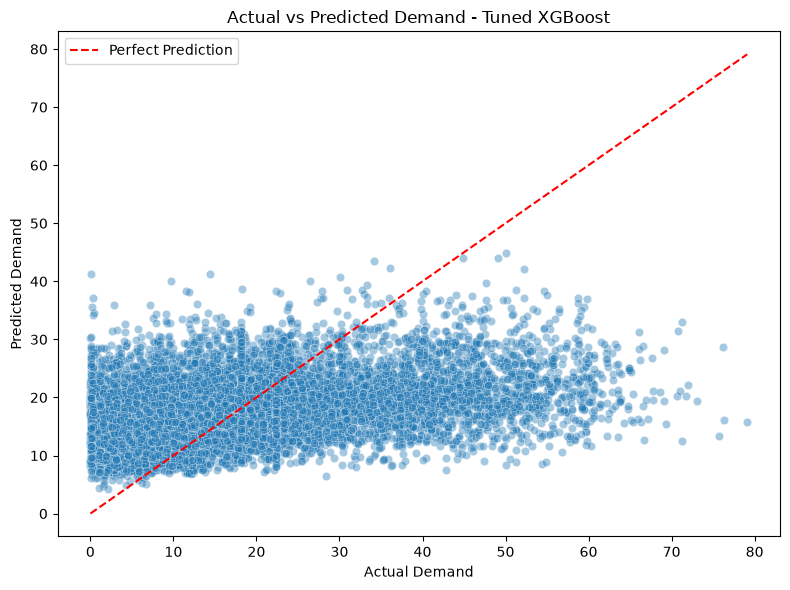

In [35]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_tuned,
    alpha=0.4
)

min_value = min(y_test.min(), y_pred_tuned.min())
max_value = max(y_test.max(), y_pred_tuned.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.title("Actual vs Predicted Demand - Tuned XGBoost")
plt.legend()
plt.tight_layout()
plt.show()

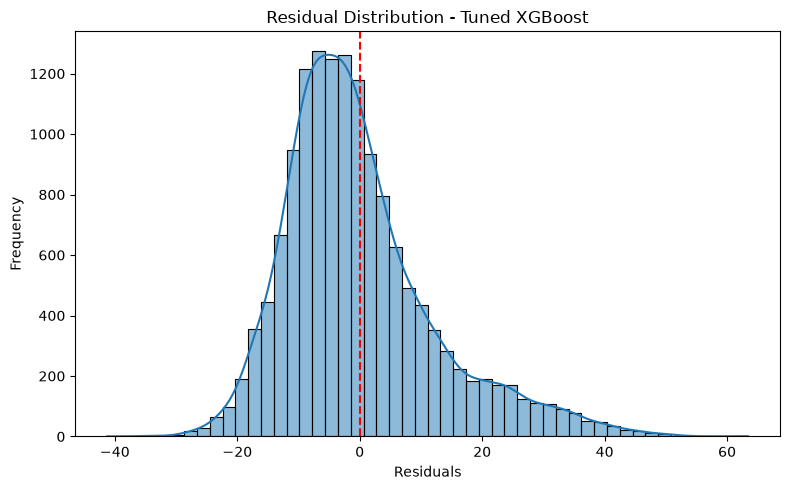

In [36]:
# Calculate residuals
residuals = y_test - y_pred_tuned

# Residual distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    bins=50,
    kde=True
)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Tuned XGBoost")

plt.tight_layout()
plt.show()

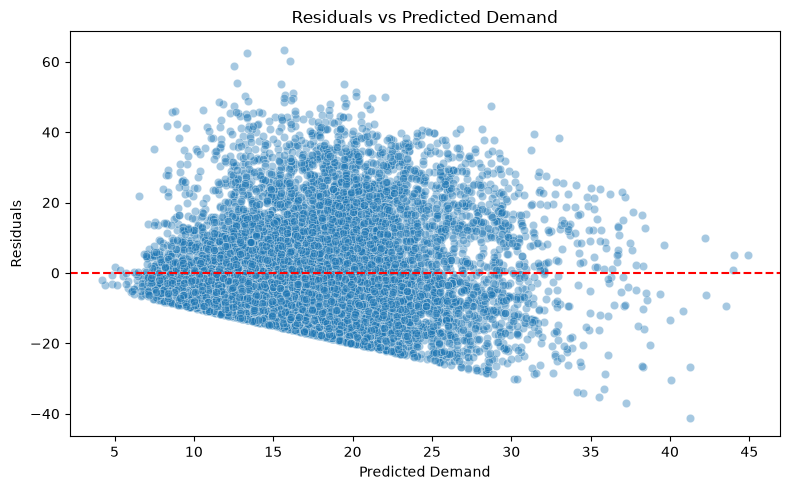

In [37]:
# Residuals vs predicted values
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_pred_tuned,
    y=residuals,
    alpha=0.4
)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted Demand")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Demand")

plt.tight_layout()
plt.show()